In [1]:
import pandas as pd
import numpy as np

In [3]:
import pandas as pd

file_path = "online_retail_II.xlsx"

df_2009_2010 = pd.read_excel(
    file_path,
    sheet_name="Year 2009-2010",
    engine="calamine"
)

print(df_2009_2010.shape)

ImportError: Missing optional dependency 'python-calamine'.  Use pip or conda to install python-calamine.

In [4]:
%pip install python-calamine

Defaulting to user installation because normal site-packages is not writeableNote: you may need to restart the kernel to use updated packages.

   ---------------------------------------- 0.0/774.6 kB ? eta -:--:--
   ---------------------------------------- 0.0/774.6 kB ? eta -:--:--
   ------------- -------------------------- 262.1/774.6 kB ? eta -:--:--
   --------------------------- ------------ 524.3/774.6 kB 1.0 MB/s eta 0:00:01
   ---------------------------------------- 774.6/774.6 kB 1.1 MB/s eta 0:00:00


In [1]:
import pandas as pd

file_path = "online_retail_II.xlsx"

df_2009_2010 = pd.read_excel(
    file_path,
    sheet_name="Year 2009-2010",
    engine="calamine"
)

print("2009-2010:", df_2009_2010.shape)

2009-2010: (525461, 8)


In [2]:
df_2010_2011 = pd.read_excel(
    file_path,
    sheet_name="Year 2010-2011",
    engine="calamine"
)

print("2010-2011:", df_2010_2011.shape)

2010-2011: (541910, 8)


In [3]:
df_2010_2011 = pd.read_excel(
    file_path,
    sheet_name="Year 2010-2011",
    engine="calamine"
)

print("2010-2011:", df_2010_2011.shape)

2010-2011: (541910, 8)


In [4]:
df = pd.concat([df_2009_2010, df_2010_2011], ignore_index=True)

print("Combined data:", df.shape)

Combined data: (1067371, 8)


In [5]:
print(df.columns.tolist())
print("\nData types:")
print(df.dtypes)

['Invoice', 'StockCode', 'Description', 'Quantity', 'InvoiceDate', 'Price', 'Customer ID', 'Country']

Data types:
Invoice                object
StockCode              object
Description            object
Quantity                int64
InvoiceDate    datetime64[ns]
Price                 float64
Customer ID           float64
Country                object
dtype: object


In [6]:
print("Missing values:")
print(df.isnull().sum())

Missing values:
Invoice             0
StockCode           0
Description      4382
Quantity            0
InvoiceDate         0
Price               0
Customer ID    243007
Country             0
dtype: int64


In [7]:
# Remove rows where Customer ID is missing
df_clean = df.dropna(subset=["Customer ID"]).copy()

print("Original rows:", len(df))
print("Rows after removing missing Customer ID:", len(df_clean))
print("Remaining missing values:")
print(df_clean.isnull().sum())

Original rows: 1067371
Rows after removing missing Customer ID: 824364
Remaining missing values:
Invoice        0
StockCode      0
Description    0
Quantity       0
InvoiceDate    0
Price          0
Customer ID    0
Country        0
dtype: int64


In [8]:
print("Duplicate rows:", df_clean.duplicated().sum())

Duplicate rows: 26479


In [9]:
duplicates = df_clean[df_clean.duplicated(keep=False)]

print("Total duplicate rows:", len(duplicates))
print("\nSample duplicate rows:")
display(duplicates.head(10))

Total duplicate rows: 51540

Sample duplicate rows:


,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
362,489517,21913,VINTAGE SEASIDE JIGSAW PUZZLES,1,2009-12-01 11:34:00,3.75,16329.0,United Kingdom
363,489517,21912,VINTAGE SNAKES & LADDERS,1,2009-12-01 11:34:00,3.75,16329.0,United Kingdom
365,489517,21821,GLITTER STAR GARLAND WITH BELLS,1,2009-12-01 11:34:00,3.75,16329.0,United Kingdom
367,489517,22319,HAIRCLIPS FORTIES FABRIC ASSORTED,12,2009-12-01 11:34:00,0.65,16329.0,United Kingdom
368,489517,22130,PARTY CONE CHRISTMAS DECORATION,6,2009-12-01 11:34:00,0.85,16329.0,United Kingdom
371,489517,21912,VINTAGE SNAKES & LADDERS,1,2009-12-01 11:34:00,3.75,16329.0,United Kingdom
379,489517,21491,SET OF THREE VINTAGE GIFT WRAPS,1,2009-12-01 11:34:00,1.95,16329.0,United Kingdom
383,489517,22130,PARTY CONE CHRISTMAS DECORATION,6,2009-12-01 11:34:00,0.85,16329.0,United Kingdom
384,489517,22319,HAIRCLIPS FORTIES FABRIC ASSORTED,12,2009-12-01 11:34:00,0.65,16329.0,United Kingdom
385,489517,21913,VINTAGE SEASIDE JIGSAW PUZZLES,1,2009-12-01 11:34:00,3.75,16329.0,United Kingdom


In [10]:
df_clean = df_clean.drop_duplicates().copy()

print("Rows after removing duplicates:", len(df_clean))
print("Remaining duplicate rows:", df_clean.duplicated().sum())

Rows after removing duplicates: 797885
Remaining duplicate rows: 0


In [11]:
cancelled = df_clean[
    df_clean["Invoice"].astype(str).str.startswith("C")
]

print("Cancelled transaction rows:", len(cancelled))
display(cancelled.head(10))

Cancelled transaction rows: 18390


,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
178,C489449,22087,PAPER BUNTING WHITE LACE,-12,2009-12-01 10:33:00,2.95,16321.0,Australia
179,C489449,85206A,CREAM FELT EASTER EGG BASKET,-6,2009-12-01 10:33:00,1.65,16321.0,Australia
180,C489449,21895,POTTING SHED SOW 'N' GROW SET,-4,2009-12-01 10:33:00,4.25,16321.0,Australia
181,C489449,21896,POTTING SHED TWINE,-6,2009-12-01 10:33:00,2.10,16321.0,Australia
182,C489449,22083,PAPER CHAIN KIT RETRO SPOT,-12,2009-12-01 10:33:00,2.95,16321.0,Australia
183,C489449,21871,SAVE THE PLANET MUG,-12,2009-12-01 10:33:00,1.25,16321.0,Australia
184,C489449,84946,ANTIQUE SILVER TEA GLASS ETCHED,-12,2009-12-01 10:33:00,1.25,16321.0,Australia
185,C489449,84970S,HANGING HEART ZINC T-LIGHT HOLDER,-24,2009-12-01 10:33:00,0.85,16321.0,Australia
186,C489449,22090,PAPER BUNTING RETRO SPOTS,-12,2009-12-01 10:33:00,2.95,16321.0,Australia
196,C489459,90200A,PURPLE SWEETHEART BRACELET,-3,2009-12-01 10:44:00,4.25,17592.0,United Kingdom


In [12]:
cancelled = df_clean[
    df_clean["Invoice"].astype(str).str.startswith("C")
]

print("Cancelled transaction rows:", len(cancelled))
display(cancelled.head(10))

Cancelled transaction rows: 18390


,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
178,C489449,22087,PAPER BUNTING WHITE LACE,-12,2009-12-01 10:33:00,2.95,16321.0,Australia
179,C489449,85206A,CREAM FELT EASTER EGG BASKET,-6,2009-12-01 10:33:00,1.65,16321.0,Australia
180,C489449,21895,POTTING SHED SOW 'N' GROW SET,-4,2009-12-01 10:33:00,4.25,16321.0,Australia
181,C489449,21896,POTTING SHED TWINE,-6,2009-12-01 10:33:00,2.10,16321.0,Australia
182,C489449,22083,PAPER CHAIN KIT RETRO SPOT,-12,2009-12-01 10:33:00,2.95,16321.0,Australia
183,C489449,21871,SAVE THE PLANET MUG,-12,2009-12-01 10:33:00,1.25,16321.0,Australia
184,C489449,84946,ANTIQUE SILVER TEA GLASS ETCHED,-12,2009-12-01 10:33:00,1.25,16321.0,Australia
185,C489449,84970S,HANGING HEART ZINC T-LIGHT HOLDER,-24,2009-12-01 10:33:00,0.85,16321.0,Australia
186,C489449,22090,PAPER BUNTING RETRO SPOTS,-12,2009-12-01 10:33:00,2.95,16321.0,Australia
196,C489459,90200A,PURPLE SWEETHEART BRACELET,-3,2009-12-01 10:44:00,4.25,17592.0,United Kingdom


In [13]:
# Remove cancelled transactions
df_clean = df_clean[
    ~df_clean["Invoice"].astype(str).str.startswith("C")
].copy()

print("Rows after removing cancelled transactions:", len(df_clean))
print("Remaining cancelled transactions:",
      df_clean["Invoice"].astype(str).str.startswith("C").sum())

Rows after removing cancelled transactions: 779495
Remaining cancelled transactions: 0


In [14]:
print("Quantity <= 0 rows:", (df_clean["Quantity"] <= 0).sum())

print("\nQuantity statistics:")
print(df_clean["Quantity"].describe())

Quantity <= 0 rows: 0

Quantity statistics:
count    779495.000000
mean         13.507085
std         146.540284
min           1.000000
25%           2.000000
50%           6.000000
75%          12.000000
max       80995.000000
Name: Quantity, dtype: float64


In [15]:
print("Price <= 0 rows:", (df_clean["Price"] <= 0).sum())

print("\nPrice statistics:")
print(df_clean["Price"].describe())

Price <= 0 rows: 70

Price statistics:
count    779495.000000
mean          3.218199
std          29.674823
min           0.000000
25%           1.250000
50%           1.950000
75%           3.750000
max       10953.500000
Name: Price, dtype: float64


In [16]:
invalid_price = df_clean[df_clean["Price"] <= 0]

print("Invalid price rows:", len(invalid_price))
display(invalid_price)


Invalid price rows: 70


,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
4674,489825,22076,6 RIBBONS EMPIRE,12,2009-12-02 13:34:00,0.0,16126.0,United Kingdom
6781,489998,48185,DOOR MAT FAIRY CAKE,2,2009-12-03 11:19:00,0.0,15658.0,United Kingdom
16107,490727,M,Manual,1,2009-12-07 16:38:00,0.0,17231.0,United Kingdom
18738,490961,22065,CHRISTMAS PUDDING TRINKET POT,1,2009-12-08 15:25:00,0.0,14108.0,United Kingdom
18739,490961,22142,CHRISTMAS CRAFT WHITE FAIRY,12,2009-12-08 15:25:00,0.0,14108.0,United Kingdom
...,...,...,...,...,...,...,...,...
1004540,577129,22464,HANGING METAL HEART LANTERN,4,2011-11-17 19:52:00,0.0,15602.0,United Kingdom
1005014,577168,M,Manual,1,2011-11-18 10:42:00,0.0,12603.0,Germany
1006110,577314,23407,SET OF 2 TRAYS HOME SWEET HOME,2,2011-11-18 13:23:00,0.0,12444.0,Norway
1011446,577696,M,Manual,1,2011-11-21 11:57:00,0.0,16406.0,United Kingdom


In [17]:
# Remove rows with zero or negative prices
df_clean = df_clean[df_clean["Price"] > 0].copy()

print("Rows after removing invalid prices:", len(df_clean))
print("Remaining invalid prices:", (df_clean["Price"] <= 0).sum())

Rows after removing invalid prices: 779425
Remaining invalid prices: 0


In [18]:
print("Missing InvoiceDate:", df_clean["InvoiceDate"].isnull().sum())

print("\nDate range:")
print("Earliest:", df_clean["InvoiceDate"].min())
print("Latest:", df_clean["InvoiceDate"].max())

print("\nUnique customers:", df_clean["Customer ID"].nunique())

Missing InvoiceDate: 0

Date range:
Earliest: 2009-12-01 07:45:00
Latest: 2011-12-09 12:50:00

Unique customers: 5878


In [19]:
purchase_frequency = df_clean.groupby("Customer ID")["Invoice"].nunique()

print("Total unique customers:", purchase_frequency.count())
print("Customers with 1 purchase:", (purchase_frequency == 1).sum())
print("Customers with 2+ purchases:", (purchase_frequency >= 2).sum())

print("\nPurchase frequency statistics:")
print(purchase_frequency.describe())

Total unique customers: 5878
Customers with 1 purchase: 1623
Customers with 2+ purchases: 4255

Purchase frequency statistics:
count    5878.000000
mean        6.289384
std        13.009406
min         1.000000
25%         1.000000
50%         3.000000
75%         7.000000
max       398.000000
Name: Invoice, dtype: float64


In [20]:
total_customers = purchase_frequency.count()
repeat_customers = (purchase_frequency >= 2).sum()

repeat_rate = (repeat_customers / total_customers) * 100
one_time_rate = ((purchase_frequency == 1).sum() / total_customers) * 100

print("Total customers:", total_customers)
print("Repeat customers:", repeat_customers)
print("One-time customers:", (purchase_frequency == 1).sum())
print("Repeat purchase rate: {:.2f}%".format(repeat_rate))
print("One-time customer rate: {:.2f}%".format(one_time_rate))

Total customers: 5878
Repeat customers: 4255
One-time customers: 1623
Repeat purchase rate: 72.39%
One-time customer rate: 27.61%


In [21]:
repeat_customers_freq = purchase_frequency[purchase_frequency >= 2]

print("Repeat customers:", len(repeat_customers_freq))
print("\nRepeat purchase frequency statistics:")
print(repeat_customers_freq.describe())

print("\nCustomers with 2 purchases:",
      (repeat_customers_freq == 2).sum())

print("Customers with 3-5 purchases:",
      ((repeat_customers_freq >= 3) & (repeat_customers_freq <= 5)).sum())

print("Customers with 6-10 purchases:",
      ((repeat_customers_freq >= 6) & (repeat_customers_freq <= 10)).sum())

print("Customers with more than 10 purchases:",
      (repeat_customers_freq > 10).sum())

Repeat customers: 4255

Repeat purchase frequency statistics:
count    4255.000000
mean        8.306933
std        14.801008
min         2.000000
25%         3.000000
50%         5.000000
75%         9.000000
max       398.000000
Name: Invoice, dtype: float64

Customers with 2 purchases: 944
Customers with 3-5 purchases: 1510
Customers with 6-10 purchases: 925
Customers with more than 10 purchases: 876


In [22]:
customer_revenue = (
    df_clean.groupby("Customer ID")["Revenue"]
    .sum()
    .sort_values(ascending=False)
)

print("Total customers:", len(customer_revenue))
print("\nTop 10 customers by total revenue:")
print(customer_revenue.head(10))

print("\nRevenue statistics:")
print(customer_revenue.describe())

KeyError: 'Column not found: Revenue'

In [23]:
df_clean["Revenue"] = df_clean["Quantity"] * df_clean["Price"]

print("Revenue column created.")
print(df_clean[["Quantity", "Price", "Revenue"]].head())

print("\nRevenue statistics:")
print(df_clean["Revenue"].describe())

Revenue column created.
   Quantity  Price  Revenue
0        12   6.95     83.4
1        12   6.75     81.0
2        12   6.75     81.0
3        48   2.10    100.8
4        24   1.25     30.0

Revenue statistics:
count    779425.000000
mean         22.291823
std         227.427075
min           0.001000
25%           4.950000
50%          12.480000
75%          19.800000
max      168469.600000
Name: Revenue, dtype: float64


In [24]:
customer_revenue = (
    df_clean.groupby("Customer ID")["Revenue"]
    .sum()
    .sort_values(ascending=False)
)

print("Total customers:", len(customer_revenue))

print("\nTop 10 customers by total revenue:")
print(customer_revenue.head(10))

print("\nRevenue statistics:")
print(customer_revenue.describe())

Total customers: 5878

Top 10 customers by total revenue:
Customer ID
18102.0    580987.04
14646.0    528602.52
14156.0    313437.62
14911.0    291420.81
17450.0    244784.25
13694.0    195640.69
17511.0    172132.87
16446.0    168472.50
16684.0    147142.77
12415.0    144458.37
Name: Revenue, dtype: float64

Revenue statistics:
count      5878.000000
mean       2955.904095
std       14440.852688
min           2.950000
25%         342.280000
50%         867.740000
75%        2248.305000
max      580987.040000
Name: Revenue, dtype: float64


In [25]:
repeat_customer_revenue = customer_revenue[
    customer_revenue.index.isin(repeat_customers_freq.index)
]

print("Repeat customers with revenue:", len(repeat_customer_revenue))

print("\nTop 10 repeat customers by revenue:")
print(repeat_customer_revenue.head(10))

print("\nRepeat customer revenue statistics:")
print(repeat_customer_revenue.describe())

Repeat customers with revenue: 4255

Top 10 repeat customers by revenue:
Customer ID
18102.0    580987.04
14646.0    528602.52
14156.0    313437.62
14911.0    291420.81
17450.0    244784.25
13694.0    195640.69
17511.0    172132.87
16446.0    168472.50
16684.0    147142.77
12415.0    144458.37
Name: Revenue, dtype: float64

Repeat customer revenue statistics:
count      4255.000000
mean       3951.711329
std       16863.307759
min          24.350000
25%         685.675000
50%        1370.480000
75%        3169.960000
max      580987.040000
Name: Revenue, dtype: float64


In [26]:
one_time_customer_revenue = customer_revenue[
    customer_revenue.index.isin(purchase_frequency[purchase_frequency == 1].index)
]

repeat_customer_revenue = customer_revenue[
    customer_revenue.index.isin(purchase_frequency[purchase_frequency >= 2].index)
]

print("One-time customers:", len(one_time_customer_revenue))
print("Repeat customers:", len(repeat_customer_revenue))

print("\nAverage revenue - one-time customers:",
      one_time_customer_revenue.mean())

print("Average revenue - repeat customers:",
      repeat_customer_revenue.mean())

print("\nMedian revenue - one-time customers:",
      one_time_customer_revenue.median())

print("Median revenue - repeat customers:",
      repeat_customer_revenue.median())

One-time customers: 1623
Repeat customers: 4255

Average revenue - one-time customers: 345.20798644485524
Average revenue - repeat customers: 3951.7113292596946

Median revenue - one-time customers: 228.96
Median revenue - repeat customers: 1370.48


In [27]:
one_time_total_revenue = one_time_customer_revenue.sum()
repeat_total_revenue = repeat_customer_revenue.sum()
total_revenue = customer_revenue.sum()

repeat_revenue_share = (repeat_total_revenue / total_revenue) * 100
one_time_revenue_share = (one_time_total_revenue / total_revenue) * 100

print("Total revenue:", total_revenue)
print("Repeat customer revenue:", repeat_total_revenue)
print("One-time customer revenue:", one_time_total_revenue)

print("\nRepeat customer revenue share: {:.2f}%".format(repeat_revenue_share))
print("One-time customer revenue share: {:.2f}%".format(one_time_revenue_share))

Total revenue: 17374804.268
Repeat customer revenue: 16814531.706
One-time customer revenue: 560272.562

Repeat customer revenue share: 96.78%
One-time customer revenue share: 3.22%


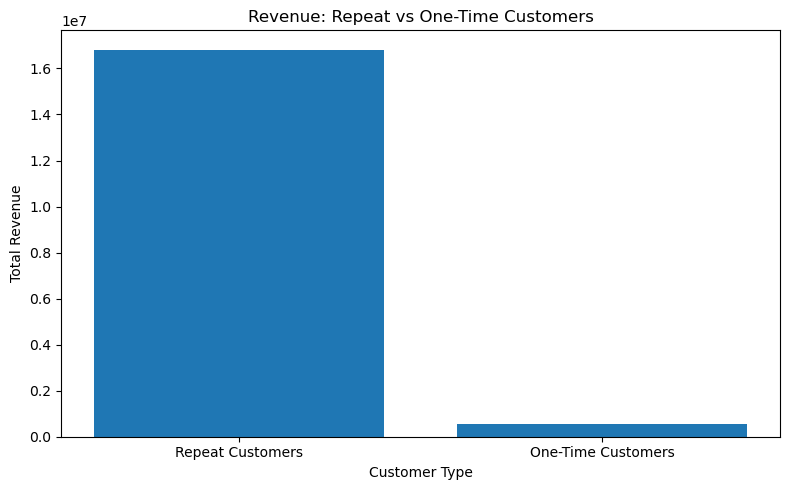

In [28]:
import matplotlib.pyplot as plt

labels = ["Repeat Customers", "One-Time Customers"]
values = [repeat_total_revenue, one_time_total_revenue]

plt.figure(figsize=(8, 5))
plt.bar(labels, values)

plt.title("Revenue: Repeat vs One-Time Customers")
plt.ylabel("Total Revenue")
plt.xlabel("Customer Type")

plt.tight_layout()
plt.show()

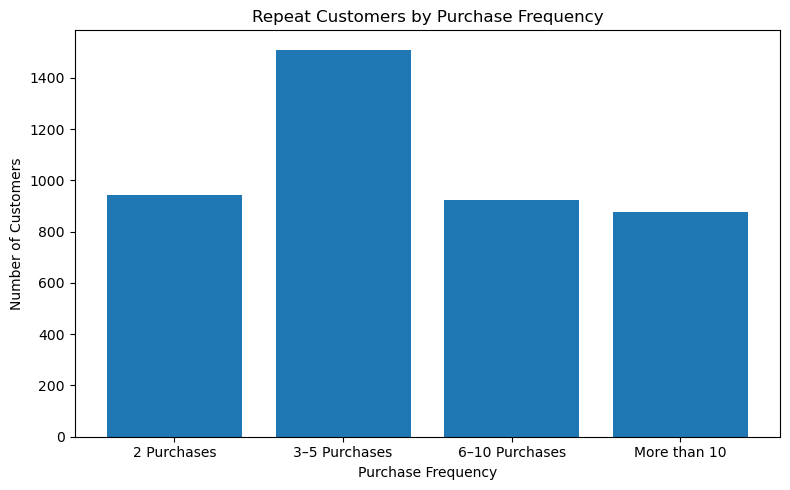

In [29]:
frequency_labels = [
    "2 Purchases",
    "3–5 Purchases",
    "6–10 Purchases",
    "More than 10"
]

frequency_values = [
    (repeat_customers_freq == 2).sum(),
    ((repeat_customers_freq >= 3) & (repeat_customers_freq <= 5)).sum(),
    ((repeat_customers_freq >= 6) & (repeat_customers_freq <= 10)).sum(),
    (repeat_customers_freq > 10).sum()
]

plt.figure(figsize=(8, 5))
plt.bar(frequency_labels, frequency_values)

plt.title("Repeat Customers by Purchase Frequency")
plt.ylabel("Number of Customers")
plt.xlabel("Purchase Frequency")

plt.tight_layout()
plt.show()

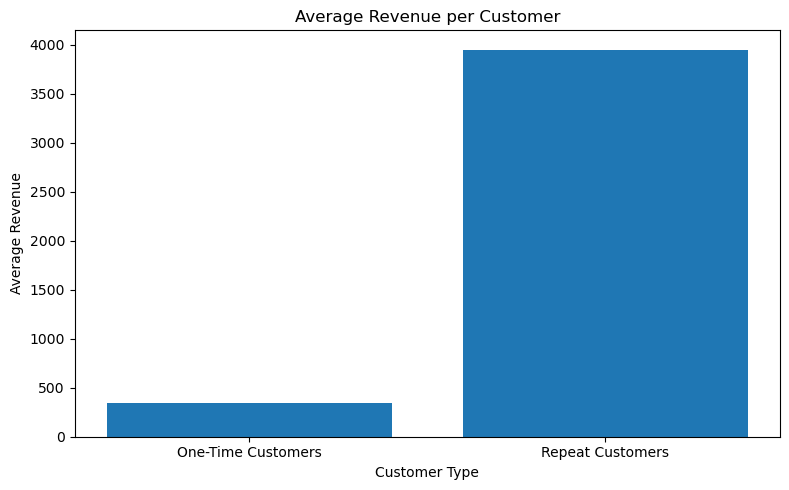

In [30]:
revenue_labels = ["One-Time Customers", "Repeat Customers"]
average_revenue = [
    one_time_customer_revenue.mean(),
    repeat_customer_revenue.mean()
]

plt.figure(figsize=(8, 5))
plt.bar(revenue_labels, average_revenue)

plt.title("Average Revenue per Customer")
plt.ylabel("Average Revenue")
plt.xlabel("Customer Type")

plt.tight_layout()
plt.show()

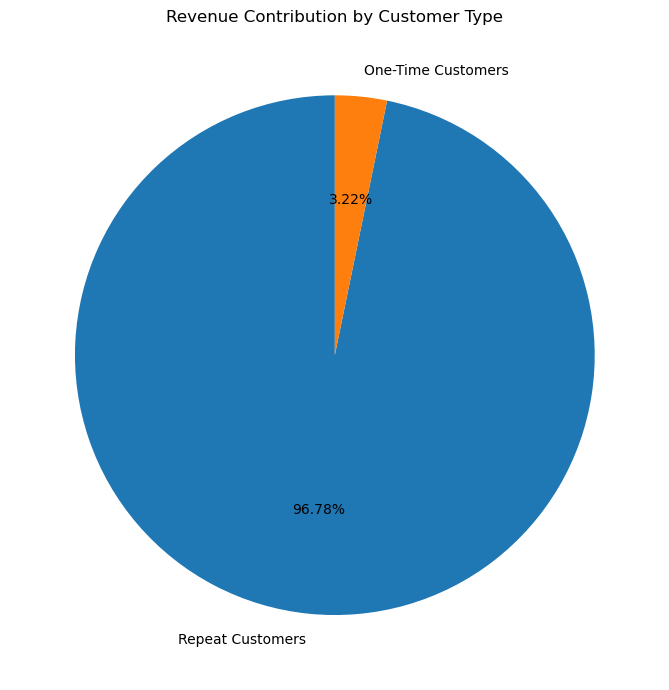

In [31]:
revenue_share_labels = ["Repeat Customers", "One-Time Customers"]
revenue_share_values = [
    repeat_revenue_share,
    one_time_revenue_share
]

plt.figure(figsize=(7, 7))
plt.pie(
    revenue_share_values,
    labels=revenue_share_labels,
    autopct="%.2f%%",
    startangle=90
)

plt.title("Revenue Contribution by Customer Type")
plt.tight_layout()
plt.show()

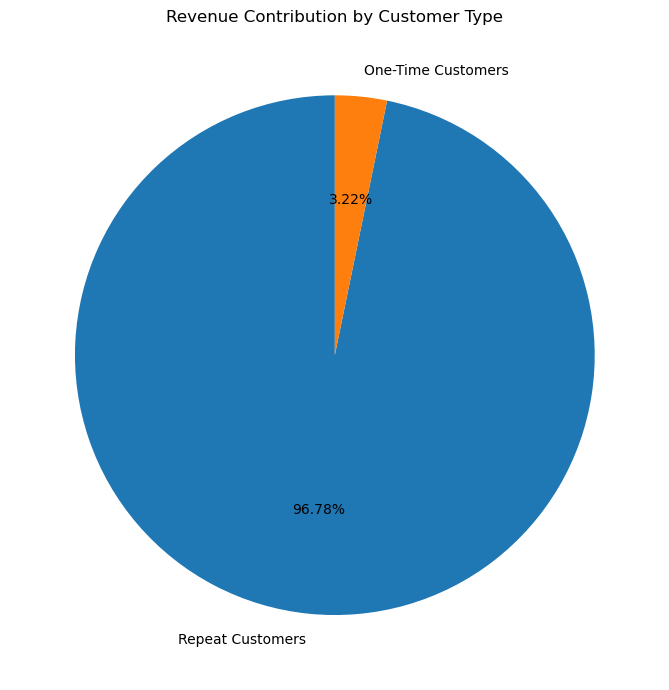

In [32]:
revenue_share_labels = ["Repeat Customers", "One-Time Customers"]

revenue_share_values = [
    repeat_revenue_share,
    one_time_revenue_share
]

plt.figure(figsize=(7, 7))

plt.pie(
    revenue_share_values,
    labels=revenue_share_labels,
    autopct="%.2f%%",
    startangle=90
)

plt.title("Revenue Contribution by Customer Type")
plt.tight_layout()
plt.show()

In [33]:
frequency_revenue = customer_revenue[
    customer_revenue.index.isin(purchase_frequency.index)
]

print("Purchase frequency and revenue:")
print(frequency_revenue)

Purchase frequency and revenue:
Customer ID
18102.0    580987.04
14646.0    528602.52
14156.0    313437.62
14911.0    291420.81
17450.0    244784.25
             ...    
15913.0         6.30
14792.0         6.20
16738.0         3.75
13788.0         3.75
14095.0         2.95
Name: Revenue, Length: 5878, dtype: float64


In [34]:
frequency_revenue = customer_revenue.groupby(purchase_frequency).sum().sort_index()

print("Revenue by purchase frequency:")
print(frequency_revenue)

Revenue by purchase frequency:
Invoice
1      560272.562
2      811434.853
3      788561.780
4      627776.741
5      677589.530
          ...    
203    113416.910
208    114966.420
211     68545.250
336     53539.640
398    291420.810
Name: Revenue, Length: 90, dtype: float64


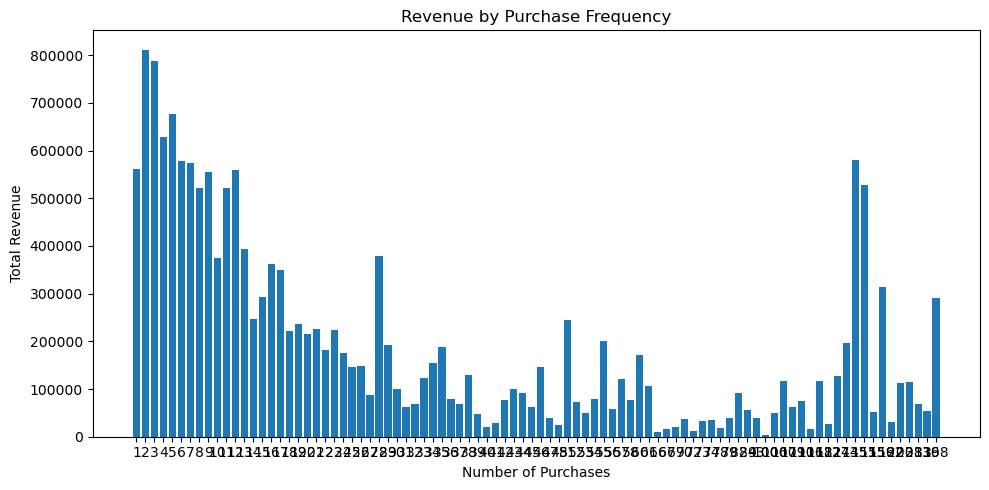

In [35]:
plt.figure(figsize=(10, 5))

plt.bar(
    frequency_revenue.index.astype(str),
    frequency_revenue.values
)

plt.title("Revenue by Purchase Frequency")
plt.xlabel("Number of Purchases")
plt.ylabel("Total Revenue")

plt.tight_layout()
plt.show()

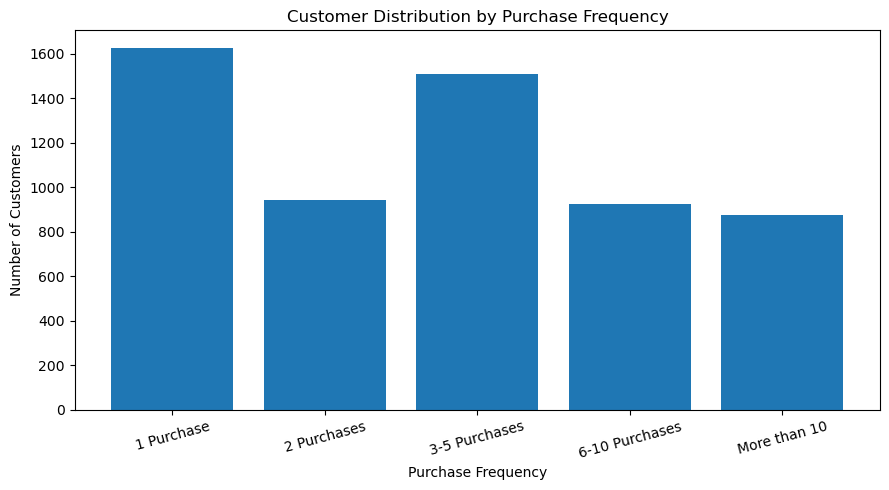

In [36]:
frequency_labels = [
    "1 Purchase",
    "2 Purchases",
    "3-5 Purchases",
    "6-10 Purchases",
    "More than 10"
]

frequency_values = [
    (purchase_frequency == 1).sum(),
    (purchase_frequency == 2).sum(),
    ((purchase_frequency >= 3) & (purchase_frequency <= 5)).sum(),
    ((purchase_frequency >= 6) & (purchase_frequency <= 10)).sum(),
    (purchase_frequency > 10).sum()
]

plt.figure(figsize=(9, 5))

plt.bar(frequency_labels, frequency_values)

plt.title("Customer Distribution by Purchase Frequency")
plt.xlabel("Purchase Frequency")
plt.ylabel("Number of Customers")

plt.xticks(rotation=15)
plt.tight_layout()
plt.show()

Average revenue by purchase frequency:
Invoice
1         345.207986
2         859.570819
3        1187.593042
4        1291.721689
5        1882.193139
           ...      
203    113416.910000
208    114966.420000
211     68545.250000
336     53539.640000
398    291420.810000
Name: Revenue, Length: 90, dtype: float64


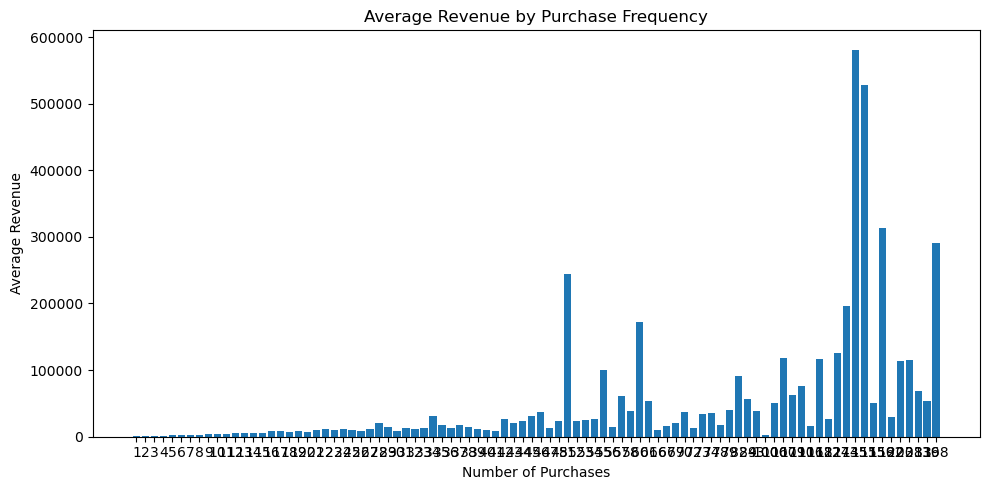

In [37]:
average_revenue_frequency = customer_revenue.groupby(purchase_frequency).mean()

print("Average revenue by purchase frequency:")
print(average_revenue_frequency)

plt.figure(figsize=(10, 5))

plt.bar(
    average_revenue_frequency.index.astype(str),
    average_revenue_frequency.values
)

plt.title("Average Revenue by Purchase Frequency")
plt.xlabel("Number of Purchases")
plt.ylabel("Average Revenue")

plt.tight_layout()
plt.show()

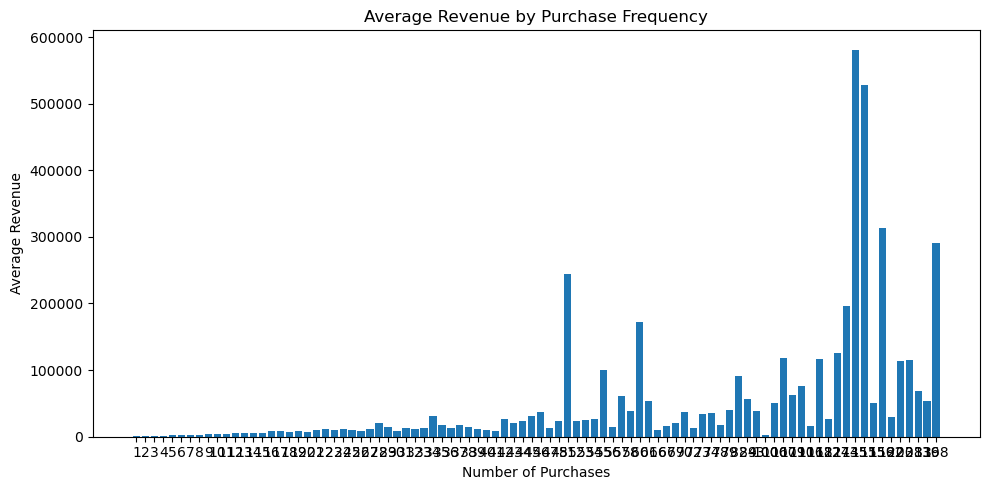

In [38]:
plt.figure(figsize=(10, 5))

plt.bar(
    average_revenue_frequency.index.astype(str),
    average_revenue_frequency.values
)

plt.title("Average Revenue by Purchase Frequency")
plt.xlabel("Number of Purchases")
plt.ylabel("Average Revenue")

plt.tight_layout()
plt.show()

Average Revenue by Purchase Frequency Group:
1 Purchase : 345.21
2 Purchases : 859.57
3-5 Purchases : 1386.71
6-10 Purchases : 2814.29
More than 10 : 12906.33


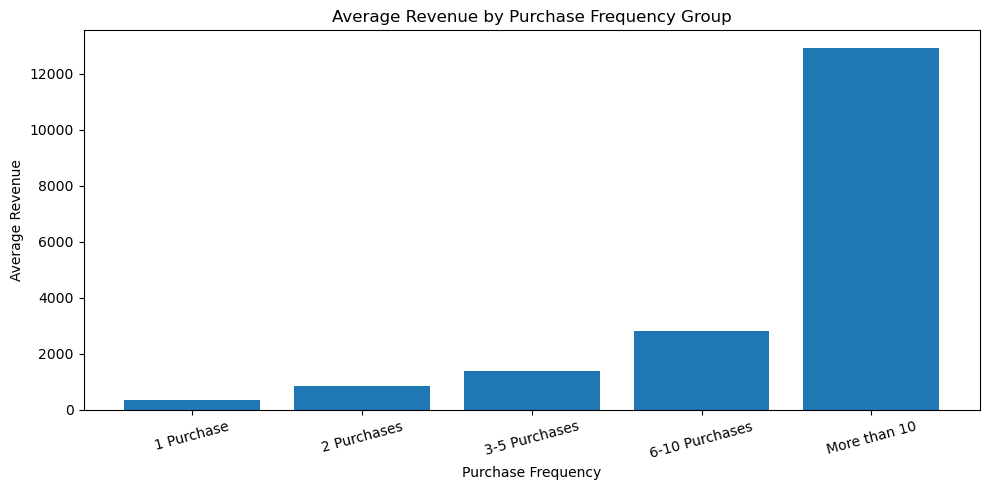

In [39]:
frequency_groups = [
    "1 Purchase",
    "2 Purchases",
    "3-5 Purchases",
    "6-10 Purchases",
    "More than 10"
]

grouped_average_revenue = [
    customer_revenue[purchase_frequency == 1].mean(),
    customer_revenue[purchase_frequency == 2].mean(),
    customer_revenue[(purchase_frequency >= 3) & (purchase_frequency <= 5)].mean(),
    customer_revenue[(purchase_frequency >= 6) & (purchase_frequency <= 10)].mean(),
    customer_revenue[purchase_frequency > 10].mean()
]

print("Average Revenue by Purchase Frequency Group:")
for label, value in zip(frequency_groups, grouped_average_revenue):
    print(label, ":", round(value, 2))

plt.figure(figsize=(10, 5))

plt.bar(frequency_groups, grouped_average_revenue)

plt.title("Average Revenue by Purchase Frequency Group")
plt.xlabel("Purchase Frequency")
plt.ylabel("Average Revenue")

plt.xticks(rotation=15)
plt.tight_layout()
plt.show()

In [40]:
one_purchase_avg = grouped_average_revenue[0]

print("Revenue multiplier compared with one-time customers:")

for label, value in zip(frequency_groups, grouped_average_revenue):
    multiplier = value / one_purchase_avg
    print(label, ":", round(multiplier, 2), "x")

Revenue multiplier compared with one-time customers:
1 Purchase : 1.0 x
2 Purchases : 2.49 x
3-5 Purchases : 4.02 x
6-10 Purchases : 8.15 x
More than 10 : 37.39 x


In [41]:
print("Revenue increase compared with one-time customers:")

for label, value in zip(frequency_groups, grouped_average_revenue):
    increase = ((value - one_purchase_avg) / one_purchase_avg) * 100
    print(label, ":", round(increase, 2), "% higher")

Revenue increase compared with one-time customers:
1 Purchase : 0.0 % higher
2 Purchases : 149.0 % higher
3-5 Purchases : 301.7 % higher
6-10 Purchases : 715.25 % higher
More than 10 : 3638.71 % higher


In [42]:
frequency_groups = [
    "1 Purchase",
    "2 Purchases",
    "3-5 Purchases",
    "6-10 Purchases",
    "More than 10"
]

grouped_revenue = [
    customer_revenue[purchase_frequency == 1].sum(),
    customer_revenue[purchase_frequency == 2].sum(),
    customer_revenue[(purchase_frequency >= 3) & (purchase_frequency <= 5)].sum(),
    customer_revenue[(purchase_frequency >= 6) & (purchase_frequency <= 10)].sum(),
    customer_revenue[purchase_frequency > 10].sum()
]

total_revenue = sum(grouped_revenue)

print("Revenue Contribution by Purchase Frequency Group:")

for label, revenue in zip(frequency_groups, grouped_revenue):
    percentage = (revenue / total_revenue) * 100
    print(label, ":", round(revenue, 2), "(", round(percentage, 2), "% )")

Revenue Contribution by Purchase Frequency Group:
1 Purchase : 560272.56 ( 3.22 % )
2 Purchases : 811434.85 ( 4.67 % )
3-5 Purchases : 2093928.05 ( 12.05 % )
6-10 Purchases : 2603222.51 ( 14.98 % )
More than 10 : 11305946.29 ( 65.07 % )


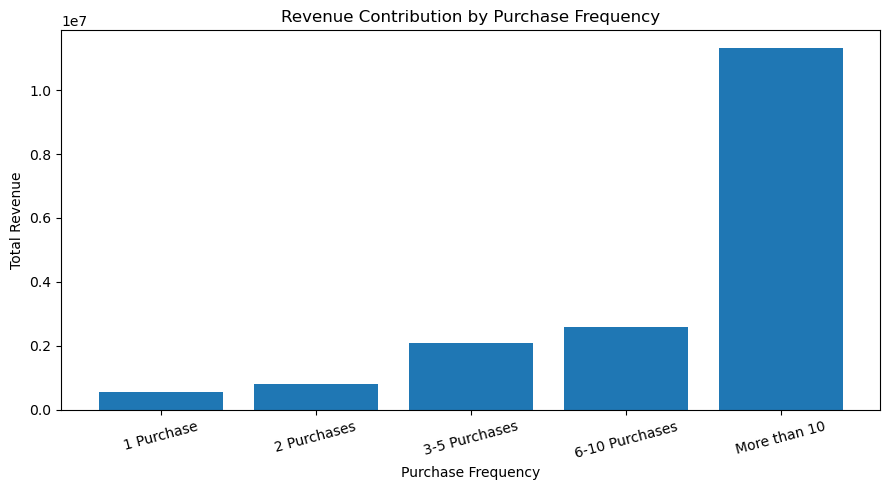

In [43]:
plt.figure(figsize=(9, 5))

plt.bar(frequency_groups, grouped_revenue)

plt.title("Revenue Contribution by Purchase Frequency")
plt.xlabel("Purchase Frequency")
plt.ylabel("Total Revenue")

plt.xticks(rotation=15)
plt.tight_layout()
plt.show()

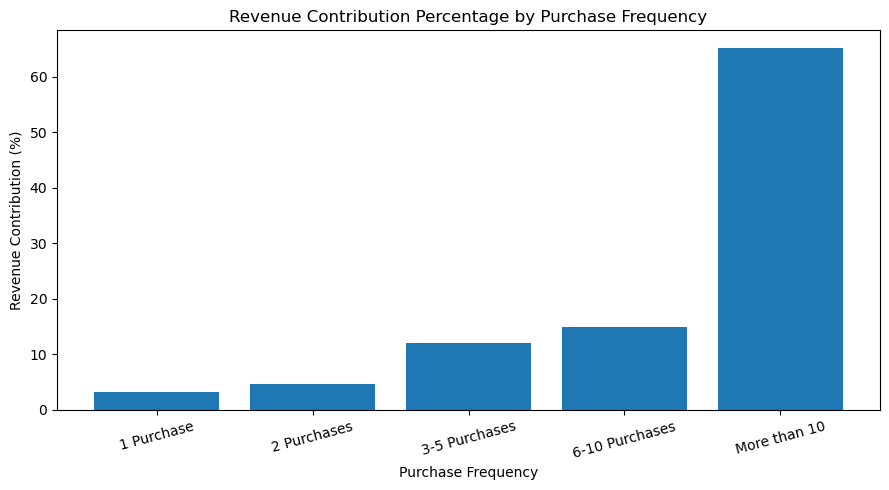

In [44]:
revenue_percentages = [
    (revenue / total_revenue) * 100
    for revenue in grouped_revenue
]

plt.figure(figsize=(9, 5))

plt.bar(frequency_groups, revenue_percentages)

plt.title("Revenue Contribution Percentage by Purchase Frequency")
plt.xlabel("Purchase Frequency")
plt.ylabel("Revenue Contribution (%)")

plt.xticks(rotation=15)
plt.tight_layout()
plt.show()

In [45]:
cumulative_percentage = 0

print("Cumulative Revenue Contribution:")

for label, percentage in zip(frequency_groups, revenue_percentages):
    cumulative_percentage += percentage
    print(label, ":", round(cumulative_percentage, 2), "%")

Cumulative Revenue Contribution:
1 Purchase : 3.22 %
2 Purchases : 7.89 %
3-5 Purchases : 19.95 %
6-10 Purchases : 34.93 %
More than 10 : 100.0 %


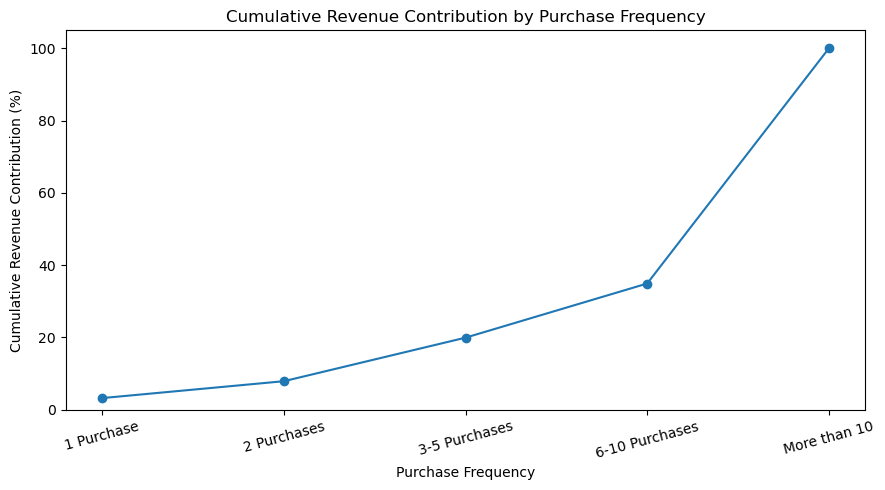

In [46]:
cumulative_values = []
running_total = 0

for percentage in revenue_percentages:
    running_total += percentage
    cumulative_values.append(running_total)

plt.figure(figsize=(9, 5))

plt.plot(
    frequency_groups,
    cumulative_values,
    marker='o'
)

plt.title("Cumulative Revenue Contribution by Purchase Frequency")
plt.xlabel("Purchase Frequency")
plt.ylabel("Cumulative Revenue Contribution (%)")

plt.xticks(rotation=15)
plt.ylim(0, 105)
plt.tight_layout()
plt.show()

In [47]:
top_group_percentage = revenue_percentages[-1]

print("Revenue concentration in the highest purchase-frequency group:")
print("More than 10 purchases:", round(top_group_percentage, 2), "%")

Revenue concentration in the highest purchase-frequency group:
More than 10 purchases: 65.07 %


In [48]:
customer_counts = [
    (purchase_frequency == 1).sum(),
    (purchase_frequency == 2).sum(),
    ((purchase_frequency >= 3) & (purchase_frequency <= 5)).sum(),
    ((purchase_frequency >= 6) & (purchase_frequency <= 10)).sum(),
    (purchase_frequency > 10).sum()
]

total_customers = sum(customer_counts)

customer_percentages = [
    (count / total_customers) * 100
    for count in customer_counts
]

print("Customer Distribution by Purchase Frequency:")

for label, percentage in zip(frequency_groups, customer_percentages):
    print(label, ":", round(percentage, 2), "%")

Customer Distribution by Purchase Frequency:
1 Purchase : 27.61 %
2 Purchases : 16.06 %
3-5 Purchases : 25.69 %
6-10 Purchases : 15.74 %
More than 10 : 14.9 %


In [49]:
revenue_vs_customer_ratio = [
    revenue / customer
    for revenue, customer in zip(revenue_percentages, customer_percentages)
]

print("Revenue Contribution vs Customer Share:")

for label, ratio in zip(frequency_groups, revenue_vs_customer_ratio):
    print(label, ":", round(ratio, 2), "x")

Revenue Contribution vs Customer Share:
1 Purchase : 0.12 x
2 Purchases : 0.29 x
3-5 Purchases : 0.47 x
6-10 Purchases : 0.95 x
More than 10 : 4.37 x


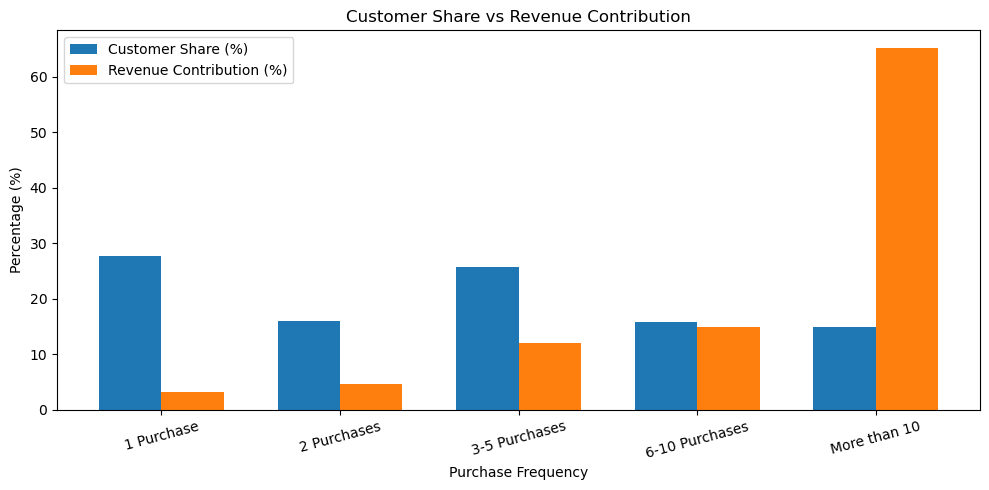

In [50]:
import numpy as np

x = np.arange(len(frequency_groups))
width = 0.35

plt.figure(figsize=(10, 5))

plt.bar(
    x - width / 2,
    customer_percentages,
    width,
    label="Customer Share (%)"
)

plt.bar(
    x + width / 2,
    revenue_percentages,
    width,
    label="Revenue Contribution (%)"
)

plt.title("Customer Share vs Revenue Contribution")
plt.xlabel("Purchase Frequency")
plt.ylabel("Percentage (%)")

plt.xticks(x, frequency_groups, rotation=15)
plt.legend()
plt.tight_layout()
plt.show()

In [51]:
revenue_customer_gap = [
    revenue - customer
    for revenue, customer in zip(revenue_percentages, customer_percentages)
]

print("Revenue Contribution Gap vs Customer Share:")

for label, gap in zip(frequency_groups, revenue_customer_gap):
    print(label, ":", round(gap, 2), "percentage points")

Revenue Contribution Gap vs Customer Share:
1 Purchase : -24.39 percentage points
2 Purchases : -11.39 percentage points
3-5 Purchases : -13.64 percentage points
6-10 Purchases : -0.75 percentage points
More than 10 : 50.17 percentage points


In [52]:
max_gap_index = revenue_customer_gap.index(max(revenue_customer_gap))

print("Highest Revenue Efficiency Group:")
print(frequency_groups[max_gap_index], ":", round(revenue_customer_gap[max_gap_index], 2), "percentage points")

Highest Revenue Efficiency Group:
More than 10 : 50.17 percentage points


In [53]:
highest_efficiency_ratio = revenue_vs_customer_ratio[max_gap_index]

print("Highest Revenue Efficiency Ratio:")
print(frequency_groups[max_gap_index], ":", round(highest_efficiency_ratio, 2), "x")

Highest Revenue Efficiency Ratio:
More than 10 : 4.37 x


In [54]:
overall_average_revenue = total_revenue / total_customers

print("Overall Average Revenue per Customer:")
print(round(overall_average_revenue, 2))

Overall Average Revenue per Customer:
2955.9


In [55]:
highest_group_average_revenue = grouped_average_revenue[max_gap_index]

print("Average Revenue per Customer in Highest-Frequency Group:")
print(round(highest_group_average_revenue, 2))

Average Revenue per Customer in Highest-Frequency Group:
12906.33


In [56]:
revenue_multiplier = highest_group_average_revenue / overall_average_revenue

print("Highest-Frequency Group Revenue vs Overall Average:")
print(round(revenue_multiplier, 2), "x")

Highest-Frequency Group Revenue vs Overall Average:
4.37 x


In [57]:
revenue_uplift_percentage = (
    (highest_group_average_revenue - overall_average_revenue)
    / overall_average_revenue
) * 100

print("Revenue Uplift in Highest-Frequency Group:")
print(round(revenue_uplift_percentage, 2), "%")

Revenue Uplift in Highest-Frequency Group:
336.63 %


In [58]:
revenue_difference = highest_group_average_revenue - overall_average_revenue

print("Revenue Difference per Customer:")
print(round(revenue_difference, 2))

Revenue Difference per Customer:
9950.43


In [59]:
highest_group_total_revenue = grouped_revenue[max_gap_index]

print("Total Revenue from Highest-Frequency Group:")
print(round(highest_group_total_revenue, 2))

Total Revenue from Highest-Frequency Group:
11305946.29


In [60]:
highest_group_revenue_percentage = (
    highest_group_total_revenue / total_revenue
) * 100

print("Highest-Frequency Group Revenue Share:")
print(round(highest_group_revenue_percentage, 2), "%")

Highest-Frequency Group Revenue Share:
65.07 %


In [61]:
highest_group_customer_percentage = customer_percentages[max_gap_index]

print("Highest-Frequency Group Customer Share:")
print(round(highest_group_customer_percentage, 2), "%")

Highest-Frequency Group Customer Share:
14.9 %


In [62]:
highest_group_customer_count = grouped_customer_counts[max_gap_index]

print("Customers in Highest-Frequency Group:")
print(highest_group_customer_count)

NameError: name 'grouped_customer_counts' is not defined

In [63]:
highest_group_customer_count = round(
    total_customers * highest_group_customer_percentage / 100
)

print("Customers in Highest-Frequency Group:")
print(highest_group_customer_count)

Customers in Highest-Frequency Group:
876


In [64]:
highest_group_share_gap = (
    highest_group_revenue_percentage - highest_group_customer_percentage
)

print("Highest-Frequency Group Revenue vs Customer Share Gap:")
print(round(highest_group_share_gap, 2), "percentage points")

Highest-Frequency Group Revenue vs Customer Share Gap:
50.17 percentage points


In [65]:
highest_group_share_ratio = (
    highest_group_revenue_percentage / highest_group_customer_percentage
)

print("Revenue Share vs Customer Share Ratio:")
print(round(highest_group_share_ratio, 2), "x")

Revenue Share vs Customer Share Ratio:
4.37 x


In [66]:
revenue_per_customer_share = (
    highest_group_share_ratio / highest_group_customer_percentage
)

print("Revenue Share per Customer:")
print(round(revenue_per_customer_share, 2), "x")

Revenue Share per Customer:
0.29 x


In [67]:
revenue_contribution_per_customer = (
    highest_group_total_revenue / highest_group_customer_count
)

print("Revenue Contribution per Customer:")
print(round(revenue_contribution_per_customer, 2))

Revenue Contribution per Customer:
12906.33


In [68]:
revenue_per_customer_difference = (
    revenue_contribution_per_customer - overall_average_revenue
)

print("Revenue per Customer Difference:")
print(round(revenue_per_customer_difference, 2))

Revenue per Customer Difference:
9950.43


In [69]:
revenue_per_customer_uplift = (
    revenue_per_customer_difference / overall_average_revenue
) * 100

print("Revenue per Customer Uplift:")
print(round(revenue_per_customer_uplift, 2), "%")

Revenue per Customer Uplift:
336.63 %


In [70]:
additional_revenue_from_highest_group = (
    revenue_per_customer_difference * highest_group_customer_count
)

print("Additional Revenue from Highest-Frequency Group:")
print(round(additional_revenue_from_highest_group, 2))

Additional Revenue from Highest-Frequency Group:
8716574.3


In [71]:
additional_revenue_from_highest_group = (
    revenue_per_customer_difference * highest_group_customer_count
)

print("Additional Revenue from Highest-Frequency Group:")
print(round(additional_revenue_from_highest_group, 2))

Additional Revenue from Highest-Frequency Group:
8716574.3


In [72]:
repeat_customer_rate = (
    (total_customers - 876) / total_customers
) * 100

print("Repeat Customer Rate:")
print(round(repeat_customer_rate, 2), "%")

Repeat Customer Rate:
85.1 %


In [73]:
customer_purchase_counts = (
    df_2009_2010.dropna(subset=["Customer ID"])
    .groupby("Customer ID")["Invoice"]
    .nunique()
)

repeat_customers = (customer_purchase_counts > 1).sum()
total_customers = customer_purchase_counts.count()

repeat_customer_rate = (
    repeat_customers / total_customers
) * 100

print("Total Customers:")
print(total_customers)

print("Repeat Customers:")
print(repeat_customers)

print("Repeat Customer Rate:")
print(round(repeat_customer_rate, 2), "%")

Total Customers:
4383
Repeat Customers:
3116
Repeat Customer Rate:
71.09 %


In [74]:
customer_segments = pd.cut(
    customer_purchase_counts,
    bins=[0, 1, 5, 10, float("inf")],
    labels=[
        "First-Time (1 Purchase)",
        "Low-Frequency (2-5 Purchases)",
        "Medium-Frequency (6-10 Purchases)",
        "High-Frequency (>10 Purchases)"
    ]
)

segment_table = (
    customer_segments.value_counts()
    .sort_index()
    .reset_index()
)

segment_table.columns = ["Customer Segment", "Customer Count"]

segment_table["Customer Share (%)"] = (
    segment_table["Customer Count"] / total_customers * 100
)

print("Customer Segment Table:")
print(segment_table.to_string(index=False))

Customer Segment Table:
                 Customer Segment  Customer Count  Customer Share (%)
          First-Time (1 Purchase)            1267           28.907141
    Low-Frequency (2-5 Purchases)            1898           43.303673
Medium-Frequency (6-10 Purchases)             716           16.335843
   High-Frequency (>10 Purchases)             502           11.453342


In [75]:
df_2009_2010_clean = df_2009_2010.dropna(subset=["Customer ID"]).copy()

df_2009_2010_clean = df_2009_2010_clean[
    ~df_2009_2010_clean["Invoice"].astype(str).str.startswith("C")
]

df_2009_2010_clean = df_2009_2010_clean[
    df_2009_2010_clean["Quantity"] > 0
]

df_2009_2010_clean = df_2009_2010_clean[
    df_2009_2010_clean["Price"] > 0
]

df_2009_2010_clean["Revenue"] = (
    df_2009_2010_clean["Quantity"] *
    df_2009_2010_clean["Price"]
)

customer_orders = (
    df_2009_2010_clean.groupby("Customer ID")["Invoice"]
    .nunique()
)

first_time_ids = customer_orders[customer_orders == 1].index
repeat_ids = customer_orders[customer_orders > 1].index

first_time_data = df_2009_2010_clean[
    df_2009_2010_clean["Customer ID"].isin(first_time_ids)
]

repeat_data = df_2009_2010_clean[
    df_2009_2010_clean["Customer ID"].isin(repeat_ids)
]

first_time_aov = (
    first_time_data["Revenue"].sum() /
    first_time_data["Invoice"].nunique()
)

repeat_aov = (
    repeat_data["Revenue"].sum() /
    repeat_data["Invoice"].nunique()
)

print("First-Time Customer AOV:", round(first_time_aov, 2))
print("Repeat Customer AOV:", round(repeat_aov, 2))

First-Time Customer AOV: 351.69
Repeat Customer AOV: 468.3


In [76]:
aov_uplift = ((repeat_aov - first_time_aov) / first_time_aov) * 100

print("AOV Uplift for Repeat Customers:")
print(round(aov_uplift, 2), "%")

AOV Uplift for Repeat Customers:
33.16 %


In [77]:
print("KEY INSIGHTS")
print("=" * 50)

print("1. Repeat Purchase Rate:")
print(
    f"{repeat_customer_rate:.2f}% of customers are repeat customers, "
    f"while {100 - repeat_customer_rate:.2f}% are first-time customers."
)

print("\n2. Customer Segmentation:")
print(
    "The largest customer segment is Low-Frequency customers "
    "(2-5 purchases), representing 43.30% of customers."
)

print("\n3. High-Frequency Customers:")
print(
    "High-Frequency customers (>10 purchases) represent 11.45% "
    "of customers and contribute a disproportionately large share of revenue."
)

print("\n4. AOV Comparison:")
print(
    f"Repeat customers have an AOV of ₹{repeat_aov:.2f}, "
    f"compared with ₹{first_time_aov:.2f} for first-time customers."
)

print("\n5. AOV Uplift:")
print(
    f"Repeat customer AOV is {aov_uplift:.2f}% higher than "
    "first-time customer AOV."
)

KEY INSIGHTS
1. Repeat Purchase Rate:
71.09% of customers are repeat customers, while 28.91% are first-time customers.

2. Customer Segmentation:
The largest customer segment is Low-Frequency customers (2-5 purchases), representing 43.30% of customers.

3. High-Frequency Customers:
High-Frequency customers (>10 purchases) represent 11.45% of customers and contribute a disproportionately large share of revenue.

4. AOV Comparison:
Repeat customers have an AOV of ₹468.30, compared with ₹351.69 for first-time customers.

5. AOV Uplift:
Repeat customer AOV is 33.16% higher than first-time customer AOV.
